# Learned matching

Models trained on the train labels; precision, recall and F1 on the validation labels.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

In [2]:
matching = pd.concat([pd.read_csv(f"results/{run}/matching.csv") for run in ["first_pass", "final"]])
matching[["run", "pair", "matcher", "threshold", "P", "R", "F1", "corr", "seconds"]]

,run,pair,matcher,threshold,P,R,F1,corr,seconds
0,first_pass,wikidata-ror,logistic regression,0.45,0.912,0.951,0.931,23546,465.1
1,first_pass,wikidata-ror,random forest,0.60,0.917,0.937,0.927,17066,490.5
2,first_pass,wikidata-ror,gradient boosting,0.60,0.897,0.923,0.910,24731,498.6
3,first_pass,wikidata-ror,logistic regression + part_word,0.45,0.912,0.951,0.931,23582,515.1
4,first_pass,wikidata-ror,random forest + part_word,0.55,0.899,0.937,0.917,21798,499.5
5,first_pass,wikidata-ror,gradient boosting + part_word,0.70,0.903,0.923,0.913,22993,504.9
6,first_pass,wikidata-ror,"logistic regression + TF-IDF, embedding",0.45,0.925,0.958,0.941,22489,515.1
7,first_pass,wikidata-ror,"random forest + TF-IDF, embedding",0.65,0.936,0.923,0.929,15826,528.7
8,first_pass,wikidata-ror,"gradient boosting + TF-IDF, embedding",0.30,0.866,0.958,0.910,30395,520.7
9,first_pass,deqar-ror,logistic regression,0.35,0.843,0.954,0.895,12754,161.8


In [3]:
def plot_matching(df, run):
    part_all = df[df["run"] == run]
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * part_all["matcher"].nunique() + 1.5), sharey=True)
    for ax, pair in zip(axes, PAIRS):
        part = part_all[part_all["pair"] == pair].set_index("matcher")[["P", "R", "F1"]]
        part.plot.barh(ax=ax, width=0.8, legend=False)
        ax.set_xlim(0, 1)
        ax.set_title(f"{run}: {pair}")
        ax.set_ylabel("")
    fig.legend(["P", "R", "F1"], loc="upper center", ncol=3)
    plt.tight_layout(rect=(0, 0, 1, 0.93))

## First pass: the three models, also with the feature part_word

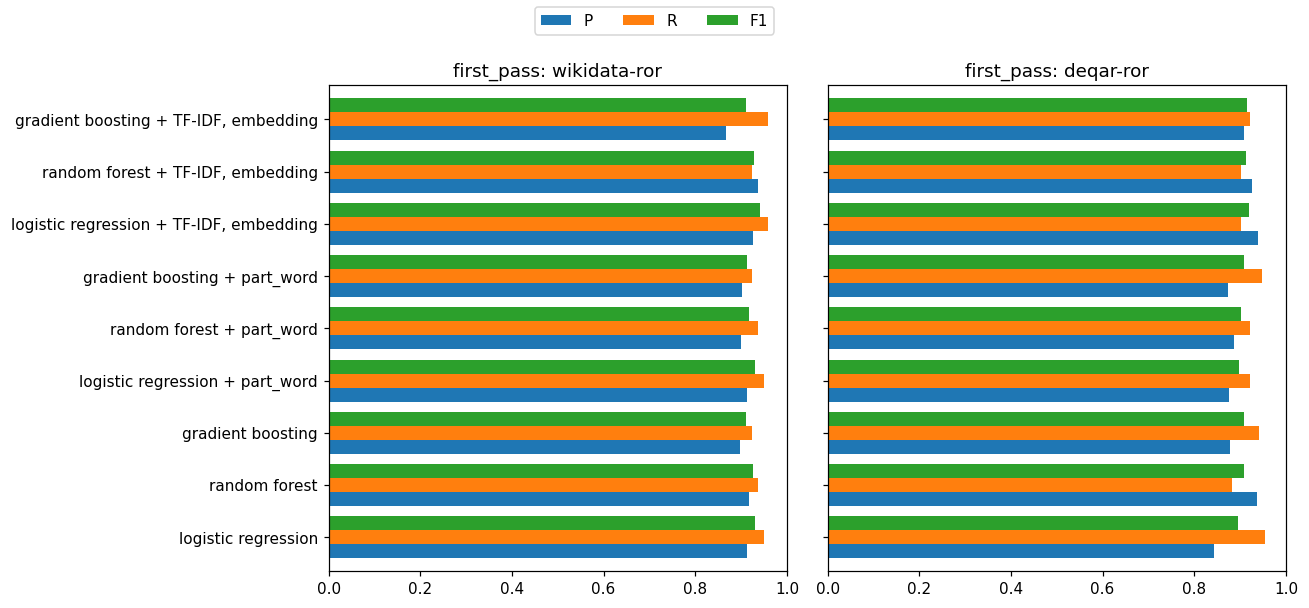

In [4]:
plot_matching(matching, "first_pass")

## Final run: the three models, also with the TF-IDF and embedding similarity of the names

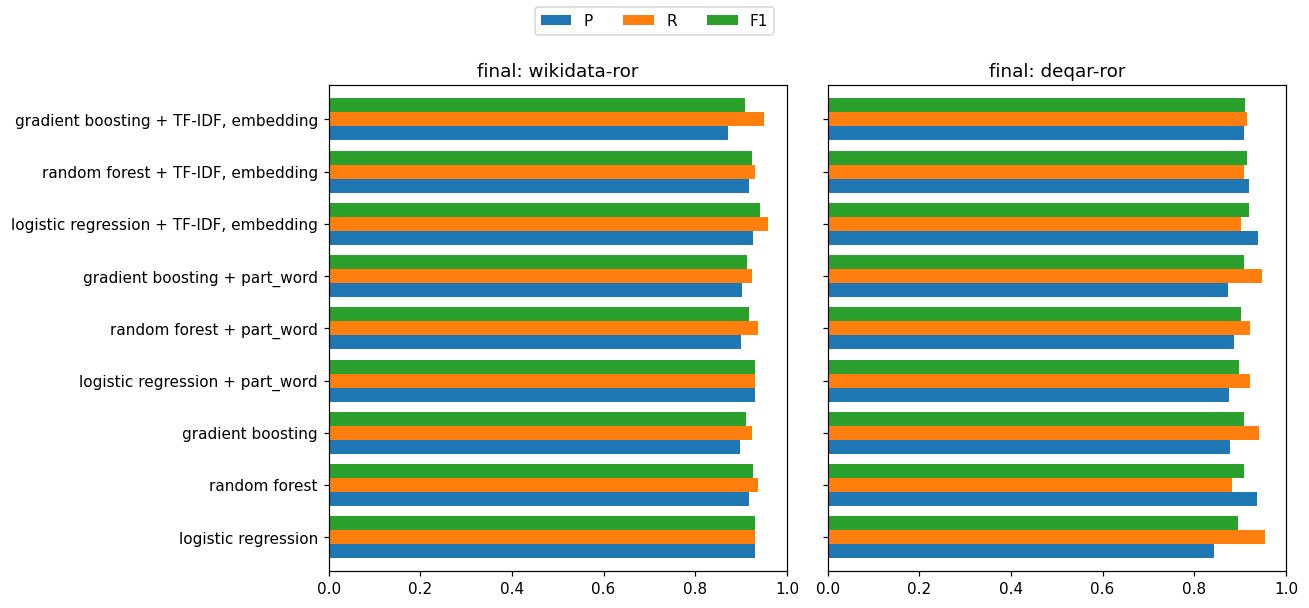

In [5]:
plot_matching(matching, "final")

## Rule-based against learned (best of each, final run)

,method,pair,matcher,P,R,F1
16,rule-based,deqar-ror,rule: names 0.5 + country 0.2 + domain 0.3,0.929,0.862,0.894
9,rule-based,wikidata-ror,"rule: all attributes (+ year, position)",0.842,0.937,0.887
15,learned,deqar-ror,"logistic regression + TF-IDF, embedding",0.938,0.901,0.919
6,learned,wikidata-ror,"logistic regression + TF-IDF, embedding",0.925,0.958,0.941


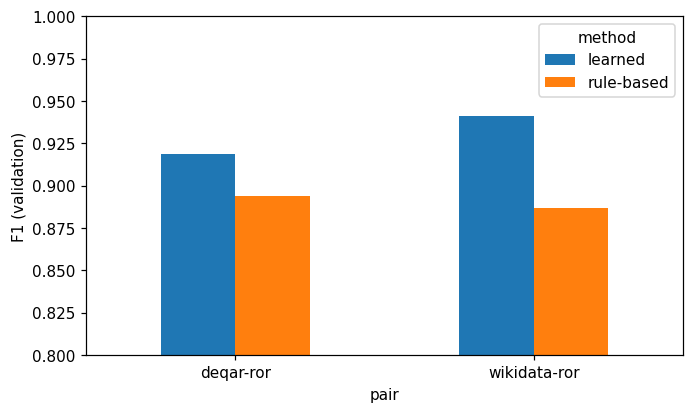

In [6]:
rules = pd.concat([pd.read_csv(f"../01_rules_string_similarity/results/{run}/matching.csv") for run in ["first_pass", "final"]])
best = []
for name, df in [("rule-based", rules), ("learned", matching)]:
    part = df[df["run"] == "final"]
    best.append(part.loc[part.groupby("pair")["F1"].idxmax()].assign(method=name))
best = pd.concat(best)
best.pivot(index="pair", columns="method", values="F1").plot.bar(rot=0, ylim=(0.8, 1), figsize=(7, 4))
plt.ylabel("F1 (validation)")
best[["method", "pair", "matcher", "P", "R", "F1"]]